## CÂU 1
**MSSV:** 24133903  
**Họ tên:** Huỳnh Trung Nghĩa

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

data_path = 'catsvdogs.xlsx'
df_cats_dogs = pd.read_excel(data_path, sheet_name='States')
df_cats_dogs.head()

,Location,Number of Households (in 1000),Percentage of households with pets,Number of Pet Households (in 1000),Percentage of Dog Owners,Dog Owning Households (1000s),Mean Number of Dogs per household,Dog Population (in 1000),Percentage of Cat Owners,Cat Owning Households,Mean Number of Cats,Cat Population
0,Alabama,1828,59.5,1088,44.1,807,1.7,1410,27.4,501,2.5,1252
1,Arizona,2515,59.5,1497,40.1,1008,1.8,1798,29.6,743,1.9,1438
2,Arkansas,1148,62.4,716,47.9,550,2.0,1097,30.6,351,2.3,810
3,California,12974,52.9,6865,32.8,4260,1.6,6687,28.3,3687,1.9,7118
4,Colorado,1986,61.3,1217,42.5,845,1.6,1349,32.3,642,1.9,1191


## 1. Đánh giá thị trường ngách

### 1a

In [16]:
top_30 = int(np.ceil(len(df_cats_dogs) * 0.30))
top_30_states = (
    df_cats_dogs.nlargest(top_30, 'Number of Pet Households (in 1000)')
    .copy()
)

top_30_states[['Location', 'Number of Pet Households (in 1000)']]

,Location,Number of Pet Households (in 1000)
3,California,6865
41,Texas,5265
8,Florida,4138
30,New York,3802
36,Pennsylvania,2942
33,Ohio,2677
11,Illinois,2602
20,Michigan,2108
9,Georgia,2093
31,North Carolina,2089


Vì dữ liệu có 49 bang, top 30% tương ứng với 15 bang. Việc dùng nlargest() giữ lại đúng các bang có quy mô hộ nuôi thú cưng lớn nhất.

### 1b

In [17]:
top_30_states['Mức độ áp đảo của Chó'] = (
    top_30_states['Percentage of Dog Owners']
    - top_30_states['Percentage of Cat Owners']
)

top_5_dog_dominance = top_30_states.nlargest(5, 'Mức độ áp đảo của Chó')
top_5_dog_dominance[[
    'Location',
    'Percentage of Dog Owners',
    'Percentage of Cat Owners',
    'Mức độ áp đảo của Chó'
]]

,Location,Percentage of Dog Owners,Percentage of Cat Owners,Mức độ áp đảo của Chó
41,Texas,44.0,28.3,15.7
40,Tennessee,44.1,29.8,14.3
23,Missouri,45.9,32.2,13.7
9,Georgia,40.1,27.3,12.8
31,North Carolina,40.3,29.5,10.8


Nhận xét: Trong nhóm 15 bang có quy mô thị trường thú cưng lớn nhất, Texas, Georgia, Tennessee, Missouri và North Carolina là 5 bang có chênh lệch tỷ lệ hộ nuôi chó so với hộ nuôi mèo cao nhất. Đây là các thị trường phù hợp để ưu tiên ngân sách cho sản phẩm dành cho chó

## 2. Phân khúc thị trường

### 2a

In [18]:
df_cats_dogs['Phân khúc'] = pd.qcut(
    df_cats_dogs['Number of Households (in 1000)'],
    q=3,
    labels=['Low', 'Medium', 'High']
)

df_cats_dogs.groupby('Phân khúc', observed=False).size().rename('Số bang')

Phân khúc
Low       17
Medium    16
High      16
Name: Số bang, dtype: int64

Sử dụng pd.qcut() để chia theo tần suất, giúp số lượng bang trong ba phân khúc xấp xỉ bằng nhau.

### 2b

In [19]:
segment_summary = (
    df_cats_dogs.groupby('Phân khúc', observed=False)
    .agg({
        'Dog Population (in 1000)': 'sum',
        'Cat Population': 'sum'
    })
    .reset_index()
)
segment_summary.columns = ['Phân khúc', 'Tổng số Chó (nghìn)', 'Tổng số Mèo (nghìn)']
segment_summary

,Phân khúc,Tổng số Chó (nghìn),Tổng số Mèo (nghìn)
0,Low,5702,6204
1,Medium,18412,19092
2,High,45180,47851


Nhận xét: Phân khúc High có tổng số chó và mèo lớn nhất vì bao gồm các bang có quy mô hộ gia đình lớn. Doanh nghiệp nên ưu tiên ngân sách theo quy mô ở phân khúc High, đồng thời dùng mức độ chênh lệch chó/mèo để điều chỉnh cơ cấu sản phẩm.

## 3. Trực quan hóa tổng số Chó và Mèo theo phân khúc

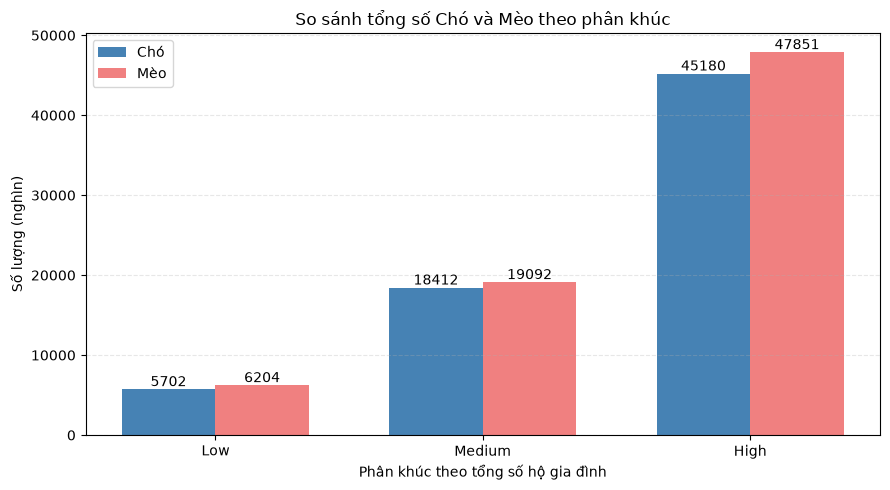

In [20]:
x = np.arange(len(segment_summary))
width = 0.35

fig, ax = plt.subplots(figsize=(9, 5))
bars_dog = ax.bar(
    x - width / 2,
    segment_summary['Tổng số Chó (nghìn)'],
    width,
    label='Chó',
    color='steelblue'
)
bars_cat = ax.bar(
    x + width / 2,
    segment_summary['Tổng số Mèo (nghìn)'],
    width,
    label='Mèo',
    color='lightcoral'
)

ax.bar_label(bars_dog, fmt='%.0f')
ax.bar_label(bars_cat, fmt='%.0f')
ax.set_xticks(x, segment_summary['Phân khúc'])
ax.set_xlabel('Phân khúc theo tổng số hộ gia đình')
ax.set_ylabel('Số lượng (nghìn)')
ax.set_title('So sánh tổng số Chó và Mèo theo phân khúc')
ax.legend()
ax.grid(axis='y', linestyle='--', alpha=0.3)
plt.tight_layout()
plt.show()

Biểu đồ cột nhóm phù hợp vì cần so sánh trực tiếp hai đại lượng (Chó và Mèo) giữa cùng ba phân khúc. Nhãn số liệu giúp đọc nhanh giá trị tổng của từng nhóm.